In [1]:
import wandb
import numpy as np
import pandas as pd
import xarray as xr
from omegaconf import OmegaConf
import itertools

from collections import defaultdict
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# Pull Data From WandB

In [10]:
ENTITY = "imos-buildingenergy-1"
PROJECT = "lmetk"

api = wandb.Api()

wandb_runs = api.runs(f"{ENTITY}/{PROJECT}")


filter_out_tags = [
    "hidden",
]

experiment_aliases = {
    "etth1": "ETTh1",
}

without_tti_experiments = list(experiment_aliases.keys())
print(without_tti_experiments)

['etth1']


In [13]:
def process_run(run, cfg):
    # print(f"Processing run: exp_name {cfg.exp_name}")

    errors = ["mae", "mse", "mape", "r2"]
    categories = ["Mean Overall"]

    keys = {}
    for e, c in itertools.product(errors, categories):
        key = f"{c}/{e}"
        if key not in run.summary.keys():
            print(f"Error: {c}/{e} not found in run.summary {run}")
        else:
            keys[key] = run.summary[key] if e != "mape" else run.summary[key] * 100

    # There is also the full history accessible:
    # a = run.history(x_axis="global_step", keys=["gerr/gen_loss_measure"]).set_index("global_step")
    # b = run.history(x_axis="global_step", keys=["gerr/gerr_L"]).set_index("global_step")
    # c = run.history(x_axis="global_step", keys=["gerr/gerr_b"]).set_index("global_step")
    # d = run.history(x_axis="global_step", keys=["train/al/mean_loss"]).set_index("global_step")
    # df = a.join(b).join(c)

    df = pd.DataFrame(keys, index=[0])
    df["seed"] = cfg.glob.seed
    df["exp_name"] = experiment_aliases[cfg.exp_name]
    df.set_index(["exp_name", "seed"], inplace=True)

    return df


def tag_filter(tags, filter_out_tags):
    for t in tags:
        if t in filter_out_tags:
            return True
    return False


runs = []
for run in tqdm(wandb_runs):
    cfg = OmegaConf.create(run.config)
    if (
        run.state == "finished"
        and ("exp_name" in cfg)
        and cfg.exp_name in without_tti_experiments
        and not tag_filter(run.tags, filter_out_tags)
    ):
        runs.append(process_run(run, cfg))

rdf = pd.concat(runs).sort_index().copy()

rdf

100%|██████████| 10/10 [00:00<00:00, 328.38it/s]


,,Mean Overall/mae,Mean Overall/mse,Mean Overall/mape,Mean Overall/r2
exp_name,seed,,,,
ETTh1,226688,0.398087,0.334109,110591.203471,0.166604


# Visualize

array([[<Axes: title={'center': 'Mean Overall/mae'}>,
        <Axes: title={'center': 'Mean Overall/mse'}>],
       [<Axes: title={'center': 'Mean Overall/mape'}>,
        <Axes: title={'center': 'Mean Overall/r2'}>]], dtype=object)

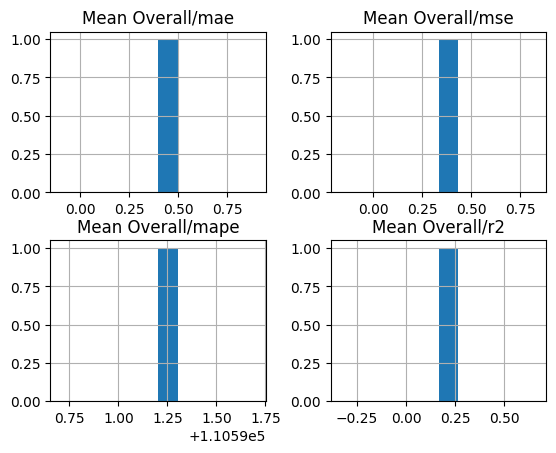

In [15]:
rdf.hist()